# Image Colorization

In [1]:
import os
os.environ["KERAS_BACKEND"] = "tensorflow"

import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import keras
from keras import layers

from skimage.color import rgb2lab, lab2rgb
from PIL import Image


# On a Mac this small model trains faster on the CPU than on the GPU,
# so we hide the GPU from TensorFlow.
if platform.system() == "Darwin":
    import tensorflow as tf
    tf.config.set_visible_devices([], "GPU")

# Same random numbers every time, so the results can be repeated
keras.utils.set_random_seed(0)
print("Keras", keras.__version__)

Keras 3.15.1


## Data

In [2]:
import kagglehub

path = kagglehub.dataset_download("akash2sharma/tiny-imagenet")

print("Path to dataset files:", path)

/opt/anaconda3/envs/keras/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Path to dataset files: /Users/nurhana/.cache/kagglehub/datasets/akash2sharma/tiny-imagenet/versions/1


In [3]:
IMG_SIZE = 64      # kuvakoko (Tiny ImageNet on valmiiksi 64x64). Vaihda tästä.
MIN_COLOR = 8      # tätä harmaammat kuvat poistetaan harjoitusdatasta

# Datan kuvat kansiosta 
def list_images(folder):
    exts = (".jpg", ".jpeg", ".png")
    files = [os.path.join(root, n) for root, _, names in os.walk(folder)
             for n in names if n.lower().endswith(exts)]
    return sorted(files)


def load_images(files, size):
    out = np.empty((len(files), size, size, 3), "uint8")
    for i, f in enumerate(files):
        img = Image.open(f).convert("RGB")
        w, h = img.size
        s = min(w, h)
        left, top = (w - s) // 2, (h - s) // 2
        img = img.crop((left, top, left + s, top + s)).resize((size, size), Image.LANCZOS)
        out[i] = np.asarray(img)
    return out

In [4]:
def colorfulness(images_u8):
    diff = images_u8.max(axis=-1) - images_u8.min(axis=-1)
    return diff.mean(axis=(1, 2))

# Muunta RGB-kuvat Lab-muotoon
def make_lab(images_u8, batch=1000):
    n, s = len(images_u8), images_u8.shape[1]
    L = np.empty((n, s, s, 1), "float32")
    ab = np.empty((n, s, s, 2), "float32")
    for i in range(0, n, batch):
        lab = rgb2lab(images_u8[i:i + batch].astype("float32") / 255)
        L[i:i + batch] = lab[..., :1] / 100
        ab[i:i + batch] = lab[..., 1:] / 128
    return L, ab


def L_ab_to_rgb(L, ab, batch=2000):
    out = np.empty(L.shape[:3] + (3,), "float32")
    for i in range(0, len(L), batch):
        lab = np.concatenate([L[i:i + batch] * 100, ab[i:i + batch] * 128], axis=-1)
        out[i:i + batch] = lab2rgb(lab)
    return out

In [5]:
# Lataa ja jakaa aineiston train, validation, test
def load_dataset(name, train_dir, test_dir, size=IMG_SIZE, max_train=None, max_test=2000,
                 val_fraction=0.1, min_color=MIN_COLOR, seed=0):
    rng = np.random.default_rng(seed)
    train_files, test_files = list_images(train_dir), list_images(test_dir)
    print(f"{name}: löytyi {len(train_files)} harjoituskuvaa ja {len(test_files)} testikuvaa")
    if not train_files or not test_files:
        raise FileNotFoundError("Kuvia ei löytynyt, tarkista kansioiden polut")

    def pick(files, n):
        idx = rng.permutation(len(files))[:n]
        return [files[i] for i in idx]

    x_trval = load_images(pick(train_files, max_train), size)
    x_te = load_images(pick(test_files, max_test), size)

    keep = colorfulness(x_trval) >= min_color
    print(f"  suodatettu pois {int((~keep).sum())} lähes harmaata kuvaa harjoitusdatasta")
    x_trval = x_trval[keep]

    n_val = int(len(x_trval) * val_fraction)
    x_val_u8, x_tr_u8 = x_trval[:n_val], x_trval[n_val:]

    data = dict(name=name, size=size,
                train=make_lab(x_tr_u8), val=make_lab(x_val_u8), test=make_lab(x_te),
                x_test=x_te.astype("float32") / 255)
    print(f"  train {len(x_tr_u8)}, val {len(x_val_u8)}, test {len(x_te)}, kuvakoko {size}x{size}")
    return data

In [6]:
def use(data):
    # Asettaa datan muuttujiin, joita train() ja evaluate() käyttävät
    global L_train, ab_train, L_val, ab_val, L_test, ab_test, x_test, gray_test
    L_train, ab_train = data["train"]
    L_val, ab_val = data["val"]
    L_test, ab_test = data["test"]
    x_test = data["x_test"]
    gray_test = L_ab_to_rgb(L_test, np.zeros_like(ab_test))
    print(f"Käytössä: {data['name']}, L_train {L_train.shape}, ab_train {ab_train.shape}")

# apu funktio, näyttä esimerrkejä käsittellyistä kuvista
def show_samples(data, n=8):
    L, ab = data["test"]
    gray = L_ab_to_rgb(L[:n], np.zeros_like(ab[:n]))
    fig, ax = plt.subplots(2, n, figsize=(1.8 * n, 3.8))
    for k in range(n):
        ax[0, k].imshow(gray[k]); ax[1, k].imshow(data["x_test"][k])
        ax[0, k].axis("off"); ax[1, k].axis("off")
    ax[0, 0].set_title("harmaa (syöte)", loc="left")
    ax[1, 0].set_title("alkuperäinen", loc="left")
    plt.show()

In [7]:
# Aineiston kansiot ja lataaminen
TINY_ROOT = os.path.join(path, "tiny-imagenet-200")      # muokkaa tulosteen mukaan
train_dir = os.path.join(TINY_ROOT, "train")
val_dir = os.path.join(TINY_ROOT, "val")

print("train:", len(list_images(train_dir)), "  val:", len(list_images(val_dir)))

train: 100000   val: 10000


TinyImageNet: löytyi 100000 harjoituskuvaa ja 10000 testikuvaa
  suodatettu pois 1778 lähes harmaata kuvaa harjoitusdatasta
  train 25400, val 2822, test 2000, kuvakoko 64x64


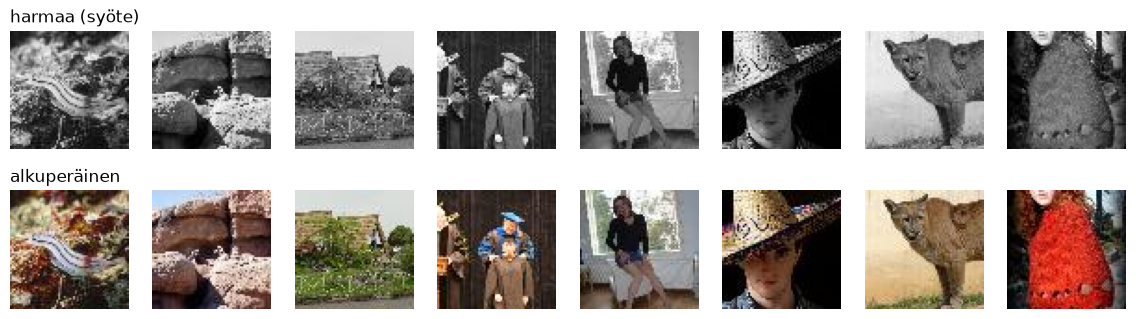

In [8]:
tiny = load_dataset("TinyImageNet", train_dir, val_dir, size=IMG_SIZE, max_train=30000)

show_samples(tiny)

In [9]:
use(tiny)

Käytössä: TinyImageNet, L_train (25400, 64, 64, 1), ab_train (25400, 64, 64, 2)


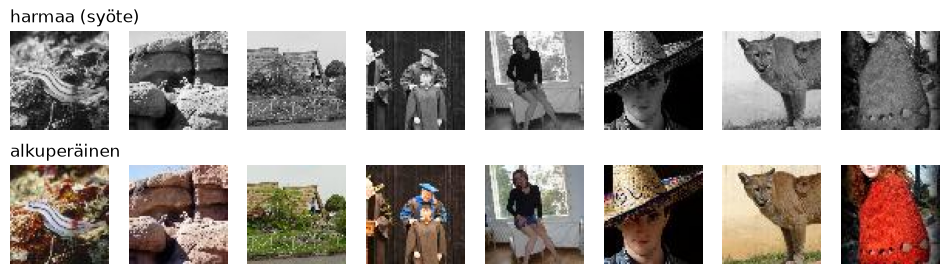

In [10]:
fig, ax = plt.subplots(2, 8, figsize=(12, 3.2))
for k in range(8):
    ax[0, k].imshow(gray_test[k])
    ax[1, k].imshow(x_test[k])
    ax[0, k].axis("off")
    ax[1, k].axis("off")
ax[0, 0].set_title("harmaa (syöte)", loc="left")
ax[1, 0].set_title("alkuperäinen", loc="left")
plt.show()

In [11]:
def psnr(images, originals):
    mse = np.mean((images - originals) ** 2)
    return 10 * np.log10(1 / mse)

def ab_error(ab_pred, ab_true):
    # keskimääräinen itseisvirhe Lab-yksiköissä (pienempi on parempi)
    return np.mean(np.abs(ab_pred - ab_true)) * 128

results = []   # (nimi, PSNR, ab-virhe)

def evaluate(name, ab_pred):
    rgb = L_ab_to_rgb(L_test, ab_pred)
    p, e = psnr(rgb, x_test), ab_error(ab_pred, ab_test)
    results.append((name, p, e))
    print(f"{name:25s} PSNR {p:.2f} dB   ab-virhe {e:.2f}")
    return rgb

_ = evaluate("harmaakuva (lähtötaso)", np.zeros_like(ab_test))

harmaakuva (lähtötaso)    PSNR 19.75 dB   ab-virhe 10.99



## Part 1: Autoencoder

In [12]:
inputs = keras.Input(shape=(64, 64, 1))

# Encoder
x = layers.Conv2D(32, 3, padding="same", activation="relu")(inputs)   
x = layers.MaxPooling2D()(x)                                           
x = layers.Conv2D(64, 3, padding="same", activation="relu")(x)       
x = layers.MaxPooling2D()(x)                                           
x = layers.Conv2D(16, 3, padding="same", activation="relu")(x)        

# Decoder
x = layers.UpSampling2D()(x)                                          
x = layers.Conv2D(64, 3, padding="same", activation="relu")(x)       
x = layers.UpSampling2D()(x)                                          
x = layers.Conv2D(32, 3, padding="same", activation="relu")(x)        
outputs = layers.Conv2D(2, 1, activation="tanh")(x)                 

autoencoder = keras.Model(inputs, outputs)
autoencoder.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 64, 64, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 64, 64, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 16)     │         9,232 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d (UpSampling2D)    │ (None, 32, 32, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 32, 32, 64)     │         9,280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_1 (UpSampling2D)  │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 64, 64, 32)     │        18,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 64, 64, 2)      │            66 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 55,858 (218.20 KB)

 Trainable params: 55,858 (218.20 KB)

 Non-trainable params: 0 (0.00 B)

In [13]:
callbacks = [
    keras.callbacks.EarlyStopping(patience=3, restore_best_weights=True),
]

autoencoder.compile(optimizer="adam", loss="mse")

history_ae = autoencoder.fit(
    L_train, ab_train,
    validation_data=(L_val, ab_val),
    epochs=10,
    batch_size=128,
    callbacks=callbacks,
    verbose=2,
)

Epoch 1/10
199/199 - 59s - 297ms/step - loss: 0.0152 - val_loss: 0.0145
Epoch 2/10
199/199 - 57s - 288ms/step - loss: 0.0147 - val_loss: 0.0143
Epoch 3/10
199/199 - 57s - 287ms/step - loss: 0.0146 - val_loss: 0.0143
Epoch 4/10
199/199 - 57s - 289ms/step - loss: 0.0145 - val_loss: 0.0142
Epoch 5/10
199/199 - 57s - 288ms/step - loss: 0.0144 - val_loss: 0.0142
Epoch 6/10
199/199 - 57s - 284ms/step - loss: 0.0144 - val_loss: 0.0141
Epoch 7/10
199/199 - 56s - 281ms/step - loss: 0.0143 - val_loss: 0.0141
Epoch 8/10
199/199 - 56s - 283ms/step - loss: 0.0143 - val_loss: 0.0140
Epoch 9/10
199/199 - 55s - 277ms/step - loss: 0.0143 - val_loss: 0.0141
Epoch 10/10
199/199 - 56s - 280ms/step - loss: 0.0142 - val_loss: 0.0140


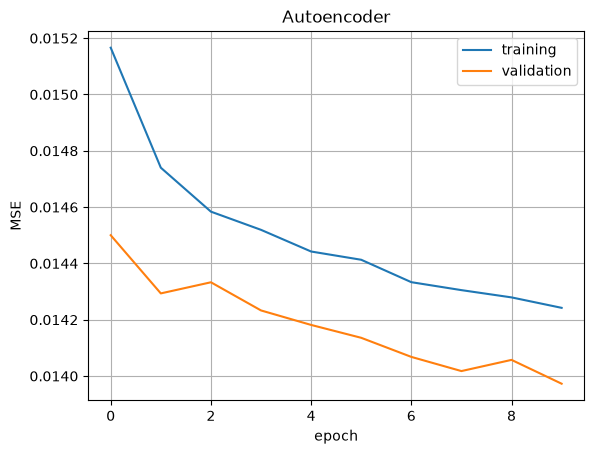

In [14]:
plt.plot(history_ae.history["loss"], label="training")
plt.plot(history_ae.history["val_loss"], label="validation")
plt.xlabel("epoch")
plt.ylabel("MSE")
plt.title("Autoencoder")
plt.grid()
plt.legend()
plt.show()

## Part 2: U-Net

In [15]:
inputs = keras.Input(shape=(64, 64, 1))                                   

# Encoder
skip1 = layers.Conv2D(32, 3, padding="same", activation="relu")(inputs)   
x = layers.MaxPooling2D()(skip1)                                          
skip2 = layers.Conv2D(64, 3, padding="same", activation="relu")(x)        
x = layers.MaxPooling2D()(skip2)                                           
x = layers.Conv2D(16, 3, padding="same", activation="relu")(x)            

# Decoder
x = layers.UpSampling2D()(x)                                              
x = layers.Concatenate()([x, skip2])                                       
x = layers.Conv2D(64, 3, padding="same", activation="relu")(x)            
x = layers.UpSampling2D()(x)                                               
x = layers.Concatenate()([x, skip1])                                       
x = layers.Conv2D(32, 3, padding="same", activation="relu")(x)            
outputs = layers.Conv2D(2, 1, activation="tanh")(x)                       
unet = keras.Model(inputs, outputs)
unet.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 64, 64, 1) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_6 (Conv2D)   │ (None, 64, 64,    │        320 │ input_layer_1[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_2     │ (None, 32, 32,    │          0 │ conv2d_6[0][0]    │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_7 (Conv2D)   │ (None, 32, 32,    │     18,496 │ max_pooling2d_2[… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_3     │ (None, 16, 16,    │          0 │ conv2d_7[0][0]    │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_8 (Conv2D)   │ (None, 16, 16,    │      9,232 │ max_pooling2d_3[… │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up_sampling2d_2     │ (None, 32, 32,    │          0 │ conv2d_8[0][0]    │
│ (UpSampling2D)      │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 32, 32,    │          0 │ up_sampling2d_2[… │
│ (Concatenate)       │ 80)               │            │ conv2d_7[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_9 (Conv2D)   │ (None, 32, 32,    │     46,144 │ concatenate[0][0] │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up_sampling2d_3     │ (None, 64, 64,    │          0 │ conv2d_9[0][0]    │
│ (UpSampling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_1       │ (None, 64, 64,    │          0 │ up_sampling2d_3[… │
│ (Concatenate)       │ 96)               │            │ conv2d_6[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_10 (Conv2D)  │ (None, 64, 64,    │     27,680 │ concatenate_1[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_11 (Conv2D)  │ (None, 64, 64, 2) │         66 │ conv2d_10[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 101,938 (398.20 KB)

 Trainable params: 101,938 (398.20 KB)

 Non-trainable params: 0 (0.00 B)

In [16]:
callbacks = [
    keras.callbacks.EarlyStopping(patience=3, restore_best_weights=True),
]

unet.compile(optimizer="adam", loss="mse")

history_unet = unet.fit(
    L_train, ab_train,
    validation_data=(L_val, ab_val),
    epochs=10,
    batch_size=128,
    callbacks=callbacks,
    verbose=2,
)

Epoch 1/10
199/199 - 95s - 477ms/step - loss: 0.0153 - val_loss: 0.0146
Epoch 2/10
199/199 - 93s - 468ms/step - loss: 0.0148 - val_loss: 0.0144
Epoch 3/10
199/199 - 96s - 482ms/step - loss: 0.0146 - val_loss: 0.0143
Epoch 4/10
199/199 - 100s - 503ms/step - loss: 0.0145 - val_loss: 0.0142
Epoch 5/10
199/199 - 100s - 505ms/step - loss: 0.0145 - val_loss: 0.0141
Epoch 6/10
199/199 - 98s - 493ms/step - loss: 0.0144 - val_loss: 0.0141
Epoch 7/10
199/199 - 96s - 482ms/step - loss: 0.0143 - val_loss: 0.0141
Epoch 8/10
199/199 - 97s - 486ms/step - loss: 0.0143 - val_loss: 0.0141
Epoch 9/10
199/199 - 97s - 486ms/step - loss: 0.0142 - val_loss: 0.0141
Epoch 10/10
199/199 - 96s - 484ms/step - loss: 0.0142 - val_loss: 0.0140


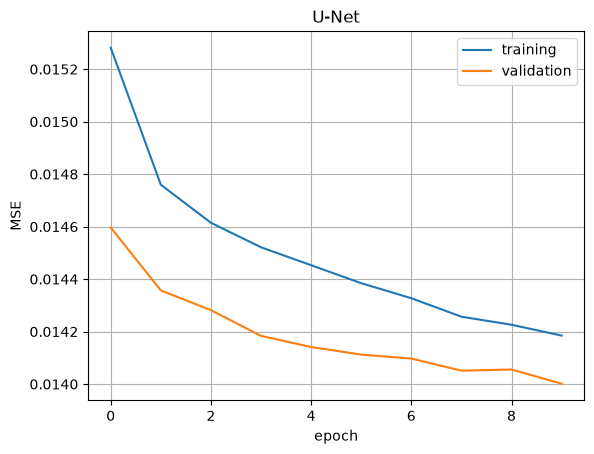

In [17]:
plt.plot(history_unet.history["loss"], label="training")
plt.plot(history_unet.history["val_loss"], label="validation")
plt.xlabel("epoch")
plt.ylabel("MSE")
plt.title("U-Net")
plt.grid()
plt.legend()
plt.show()

In [18]:
results = []
_ = evaluate("harmaakuva (lähtötaso)", np.zeros_like(ab_test))
restored_ae = evaluate("autoencoder (MSE)", autoencoder.predict(L_test, verbose=0))
restored_unet = evaluate("U-Net (MSE)", unet.predict(L_test, verbose=0))
pd.DataFrame(results, columns=["malli", "PSNR (dB)", "ab-virhe"]).round(2)

harmaakuva (lähtötaso)    PSNR 19.75 dB   ab-virhe 10.99
autoencoder (MSE)         PSNR 20.74 dB   ab-virhe 10.10
U-Net (MSE)               PSNR 20.75 dB   ab-virhe 10.11


,malli,PSNR (dB),ab-virhe
0,harmaakuva (lähtötaso),19.75,10.99
1,autoencoder (MSE),20.74,10.10
2,U-Net (MSE),20.75,10.11


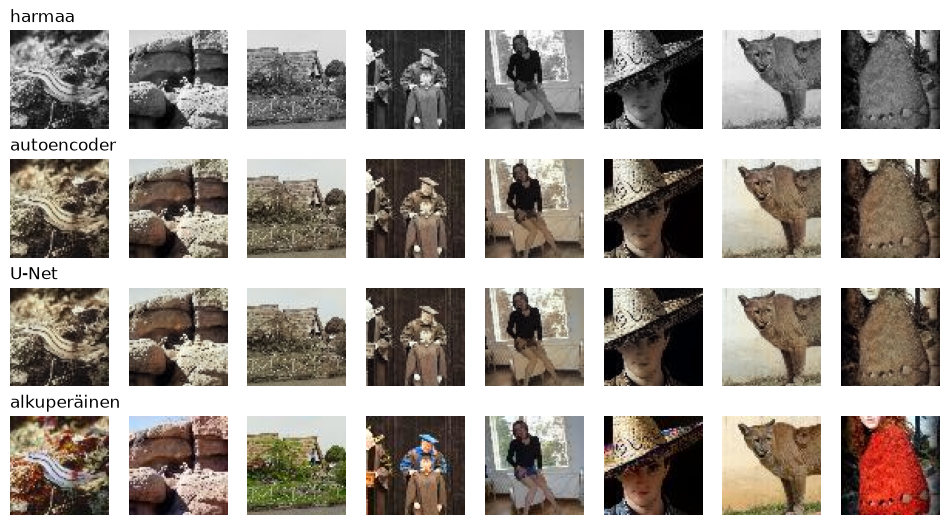

In [19]:
fig, ax = plt.subplots(4, 8, figsize=(12, 6.4))
for k in range(8):
    for r, img in enumerate([gray_test, restored_ae, restored_unet, x_test]):
        ax[r, k].imshow(img[k])
        ax[r, k].axis("off")
for r, name in enumerate(["harmaa", "autoencoder", "U-Net", "alkuperäinen"]):
    ax[r, 0].set_title(name, loc="left")
plt.show()

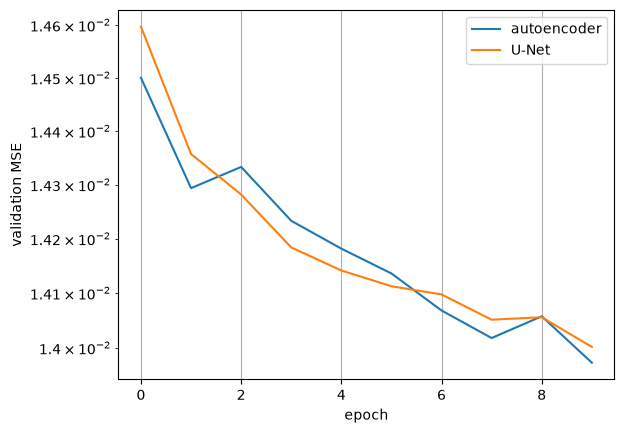

In [20]:
plt.plot(history_ae.history["val_loss"], label="autoencoder")
plt.plot(history_unet.history["val_loss"], label="U-Net")
plt.xlabel("epoch")
plt.ylabel("validation MSE")
plt.yscale("log")
plt.grid()
plt.legend()
plt.show()